# 2. Готовые модели

Сравниваем трех судей на 512 парах из разных групп. Исключаем группы из train и опубликованных выборок PairJudge. ArenaJudge мог видеть эти примеры при обучении.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from experiments.metrics import quality, paired_loss

files = Path("experiments/reports/hw2")
names = ["A", "B", "tie"]

### Пилот на 187 парах

Берем общие ID из validation ДЗ1 и теста авторов PairJudge.

In [2]:
def probs(frame, model):
    columns = [f"{model}_{label}" for label in names]
    p = frame[columns].to_numpy()
    assert np.isfinite(p).all()
    return p

pilot = pd.read_csv(files / "pilot_pairs.csv", dtype={"id": str})
y_pilot = pilot.target.to_numpy()
pilot_lr = probs(pilot, "p")
pilot_pair = probs(pilot, "judge")
display(pd.DataFrame({"TF-IDF ДЗ1": quality(y_pilot, pilot_lr),
                      "PairJudge": quality(y_pilot, pilot_pair)}).T.round(5))
pd.Series(paired_loss(y_pilot, pilot_pair, pilot_lr, pilot.group)).round(5)

,log_loss,accuracy,macro_f1
TF-IDF ДЗ1,1.18811,0.42246,0.41960
PairJudge,1.06533,0.41711,0.39264


delta      -0.12278
low        -0.19995
high       -0.04625
level       0.95000
rows      187.00000
groups    175.00000
dtype: float64

### Проверка гипотез

Для двух основных сравнений берем парные интервалы 97,5%. Для абляций и остальных сравнений берем 95%.

In [4]:
all_preds = pd.read_csv(files / "predictions.csv.gz", dtype={"id": str})
assert all_preds.id.is_unique
text_test = all_preds.loc[all_preds.bert_A.notna()]
judges = text_test.loc[text_test.pair_A.notna()]

def show_scores(frame, models):
    rows = {model: quality(frame.target, probs(frame, model)) for model in models}
    return pd.DataFrame(rows).T

print("Весь holdout", len(all_preds), "текстовые пары", len(text_test), "тест судей", len(judges))
counts = judges.target.value_counts().reindex(range(len(names)), fill_value=0)
counts.set_axis(names)

Весь holdout 11616 текстовые пары 1799 тест судей 512


A      161
B      148
tie    203
Name: count, dtype: int64

In [5]:
tables = {
    "Все строки": show_scores(all_preds, ["hw1", "tfidf_fallback", "bert_fallback"]),
    "Текстовые пары": show_scores(text_test, ["prior", "tfidf", "short_tfidf", "bert"]),
    "Новые группы": show_scores(judges, ["prior", "tfidf", "bert", "pair", "panda", "mixture"]),
    "ArenaJudge, возможно пересечение": show_scores(judges, ["arena"]),
}
table = pd.concat(tables, names=["выборка", "модель"])
table.to_csv(files / "metrics.csv")
table.round(5)

log_loss  accuracy  macro_f1
выборка                          модель                                      
Все строки                       hw1              1.13011   0.43061   0.42701
                                 tfidf_fallback   1.12724   0.42794   0.42511
                                 bert_fallback    1.13029   0.41977   0.41707
Текстовые пары                   prior            1.09556   0.37132   0.18052
                                 tfidf            1.06579   0.44080   0.43794
                                 short_tfidf      1.07480   0.43802   0.43524
                                 bert             1.08543   0.38799   0.35112
Новые группы                     prior            1.09207   0.39648   0.18928
                                 tfidf            1.01771   0.48047   0.47502
                                 bert             1.08731   0.39258   0.35999
                                 pair             1.06610   0.41992   0.41156
                                 panda            1.59029   0.42773   0.41294
                                 mixture          1.06525   0.44141   0.44227
ArenaJudge, возможно пересечение arena            0.91495   0.55664   0.55060

### Две абляции на 512 парах

Из среднего BERT и PairJudge по очереди убираем одну модель. Положительная разница означает, что log loss вырос.

In [6]:
def comparison(frame, model, reference, level=0.95, group="group"):
    y = frame.target.to_numpy()
    return paired_loss(y, probs(frame, model), probs(frame, reference), frame[group], level)

# В последней проверке групируем по связям запросов и ответов.
strict = text_test.loc[~text_test.connected_to_train]
effects = pd.DataFrame({
    "H1, BERT минус TF-IDF": comparison(text_test, "bert", "tfidf", 0.975),
    "H2, PairJudge минус BERT": comparison(judges, "pair", "bert", 0.975),
    "Без PairJudge минус смесь": comparison(judges, "bert", "mixture"),
    "Без BERT минус смесь": comparison(judges, "pair", "mixture"),
    "PandaLM минус BERT": comparison(judges, "panda", "bert"),
    "BERT с заменой минус ДЗ1": comparison(all_preds, "bert_fallback", "hw1"),
    "BERT минус TF-IDF с той же длиной": comparison(text_test, "bert", "short_tfidf"),
    "H1 без общих пар ответов": comparison(strict, "bert", "tfidf", group="component"),
}).T
effects.to_csv(files / "differences.csv")
effects.round(5)

,delta,low,high,level,rows,groups
"H1, BERT минус TF-IDF",0.01964,-0.00631,0.04613,0.975,1799.0,1483.0
"H2, PairJudge минус BERT",-0.02121,-0.05123,0.00841,0.975,512.0,512.0
Без PairJudge минус смесь,0.02206,0.00861,0.03549,0.950,512.0,512.0
Без BERT минус смесь,0.00085,-0.01205,0.01393,0.950,512.0,512.0
PandaLM минус BERT,0.50298,0.37135,0.64329,0.950,512.0,512.0
BERT с заменой минус ДЗ1,0.00017,-0.00471,0.00503,0.950,11616.0,10200.0
BERT минус TF-IDF с той же длиной,0.01063,-0.01227,0.03352,0.950,1799.0,1483.0
H1 без общих пар ответов,0.02086,-0.00210,0.04332,0.950,1699.0,1474.0


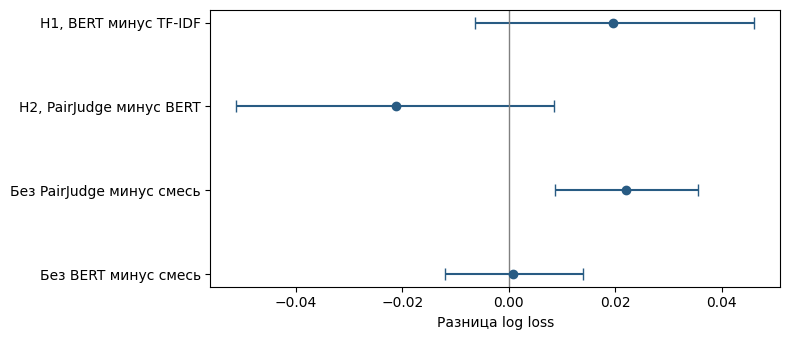

In [7]:
chart = effects.iloc[:4].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(chart.delta, range(len(chart)), xerr=[chart.delta-chart.low, chart.high-chart.delta],
            fmt="o", capsize=4, color="#285b83")
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(range(len(chart)), chart.index)
ax.set_xlabel("Разница log loss")
fig.tight_layout()
fig.savefig(files / "comparison.png", dpi=150)
plt.show()

In [8]:
errors = {}
target = judges.target.to_numpy()
for model in ["tfidf", "bert", "pair", "panda", "arena"]:
    p = probs(judges, model)
    wrong = p.argmax(1) != target
    errors[model] = [wrong.sum(), (wrong & (p.max(1) >= 0.9)).sum()]

errors = pd.DataFrame(errors, index=["ошибок", "из них с вероятностью от 90%"]).T
errors.to_csv(files / "errors.csv")
errors

,ошибок,из них с вероятностью от 90%
tfidf,266,0
bert,311,0
pair,297,0
panda,293,17
arena,227,0


PairJudge получил 1,0661, BERT 1,0873, TF-IDF 1,0177. У смеси 1,0653. Без PairJudge log loss вырос на 0,0221. Без BERT он изменился на 0,0008, интервал включает ноль. У PandaLM 17 уверенных ошибок с вероятностью от 90%.

In [9]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("preferences-hw2")
with mlflow.start_run(run_name="BERT и три судьи") as tracked:
    cfg = json.loads((files / "config.json").read_text())
    mlflow.log_params({k: v for k, v in cfg.items() if k != "models"})
    for name, (_, revision) in cfg["models"].items():
        mlflow.log_param(name + "_revision", revision)
    scopes = dict(zip(tables, ["full", "text", "judges", "overlap_risk"]))
    for (scope, name), row in table.iterrows():
        mlflow.log_metrics({f"{scopes[scope]}.{name}.{k}": float(v) for k, v in row.items()})
    for f in ["config.json", "protocol.md", "metrics.csv", "differences.csv", "learning.csv",
              "batches.csv", "comparison.png", "predictions.csv.gz", "errors.csv", "judge_ids.csv"]:
        mlflow.log_artifact(str(files / f))
    print("MLflow", tracked.info.run_id)

MLflow d733d0091c954da6a1f35d7053d95f68


## Повтор эксперимента

### Данные и модели

Нужны artifacts/hw2-input и сохраненный запуск BERT из первого ноутбука.

In [ ]:
%pip install torch==2.8.0 transformers==4.57.6 huggingface-hub==0.36.2 pairjudge==0.3.0 onnxruntime==1.23.2 sentencepiece==0.2.1 pandas==2.3.3

In [ ]:
import gc
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

bundle = Path("artifacts/hw2-input")
run = Path((bundle / "bert_run.txt").read_text())
models = json.loads((run / "config.json").read_text())["models"]
valid = pd.read_json(bundle / "valid.jsonl", lines=True, dtype={"id": str}).set_index("id")
fields = ["prompt", "response_a", "response_b"]

In [ ]:
labels3 = ["A", "B", "tie"]
def save_predictions(name, ids, values):
    values = np.asarray(values, dtype=np.float64)
    assert len(ids) and values.shape == (len(ids), 3) and pd.Index(ids).is_unique
    assert np.isfinite(values).all() and (values >= 0).all() and np.allclose(values.sum(1), 1, atol=1e-5)
    frame = pd.DataFrame(values / values.sum(axis=1, keepdims=True), index=ids, columns=labels3)
    frame.index.name = "id"
    frame.to_csv(run / (name + ".csv"))

### Готовые судьи

PandaLM сравнивает продолжения «1», «2» и «Tie» с переводом строки. Учитываем все токены каждого варианта. Порядок классов A, B, ничья.

In [3]:
from huggingface_hub import snapshot_download

judge_ids = pd.read_csv(bundle / "judge_ids.csv", dtype={"id": str}).id
judge_rows = valid.loc[judge_ids]
judge_text = judge_rows[fields].map("\n".join)
print("Новых пар", len(judge_ids))

Новых пар 512


In [4]:
from pairjudge import PairwiseJudge

pair = PairwiseJudge.from_pretrained(models["pair"][0], revision=models["pair"][1], device="cuda")
start = time.perf_counter()
pair_proba = pair.predict_proba(judge_rows[fields], swap_debias=False, batch_size=8)
save_predictions("pair", judge_ids, pair_proba)
print("PairJudge", len(pair_proba), "пар,", round(time.perf_counter() - start, 1), "с")
del pair
gc.collect()
torch.cuda.empty_cache()

PairJudge 512 пар, 3.9 с


In [5]:
import onnxruntime as ort

arena_repo, arena_rev = models["arena"]
arena_path = Path(snapshot_download(arena_repo, revision=arena_rev, allow_patterns=["*.onnx", "*.data", "*.json", "*.txt"]))
arena_cfg = json.loads((arena_path / "demo_config.json").read_text())
assert arena_cfg["labels"] == ["Response A wins", "Response B wins", "Tie"]
from tokenizers import Tokenizer
arena_tok = Tokenizer.from_file(str(arena_path / "tokenizer.json"))
arena_tok.no_padding()
arena_tok.no_truncation()
opts = ort.SessionOptions()
opts.intra_op_num_threads = 4
opts.inter_op_num_threads = 1
arena = ort.InferenceSession(str(arena_path / arena_cfg["onnx_file"]), opts, providers=["CPUExecutionProvider"])
headers = {k: arena_tok.encode(v, add_special_tokens=False).ids for k, v in arena_cfg["headers"].items()}

In [6]:
def arena_score(question, a, b):
    ids = []
    for key, text, limit in zip(["prompt", "a", "b"], [question, a, b],
                                [arena_cfg["max_p"], arena_cfg["max_r"], arena_cfg["max_r"]]):
        ids.extend(headers[key])
        ids.extend(arena_tok.encode(text, add_special_tokens=False).ids[:limit])
    arr = np.asarray([ids + headers["q"]], dtype=np.int64)
    return arena.run(["probs"], {"input_ids": arr, "attention_mask": np.ones_like(arr)})[0][0]

In [4]:
def score_rows(name, score):
    file = run / (name + "-progress.csv")
    seen = set(pd.read_csv(file, dtype={"id": str}).id) if file.exists() else set()
    for start in range(0, len(judge_text), 16):
        block = judge_text.iloc[start:start + 16]
        block = block.loc[~block.index.isin(seen)]
        if len(block):
            probs = [score(*row) for row in block.itertuples(index=False, name=None)]
            pd.DataFrame(probs, index=block.index, columns=labels3).to_csv(
                file, mode="a", header=not file.exists(), index_label="id")
            print(name, start + len(block), "/", len(judge_text), flush=True)
    done = pd.read_csv(file, dtype={"id": str}).set_index("id")
    assert done.index.is_unique and set(done.index) == set(judge_ids)
    save_predictions(name, judge_ids, done.loc[judge_ids, labels3].to_numpy())

In [7]:
score_rows("arena", arena_score)

arena 16 / 512
arena 32 / 512
arena 48 / 512
arena 64 / 512
arena 80 / 512
arena 96 / 512
arena 112 / 512
arena 128 / 512
arena 144 / 512
arena 160 / 512
arena 176 / 512
arena 192 / 512
arena 208 / 512
arena 224 / 512
arena 240 / 512
arena 256 / 512
arena 272 / 512
arena 288 / 512
arena 304 / 512
arena 320 / 512
arena 336 / 512
arena 352 / 512
arena 368 / 512
arena 384 / 512
arena 400 / 512
arena 416 / 512
arena 432 / 512
arena 448 / 512
arena 464 / 512
arena 480 / 512
arena 496 / 512
arena 512 / 512


In [5]:
from transformers import AutoModelForCausalLM

panda_repo, panda_rev = models["panda"]
panda_tok = AutoTokenizer.from_pretrained(panda_repo, revision=panda_rev, use_fast=False)
panda = AutoModelForCausalLM.from_pretrained(panda_repo, revision=panda_rev,
                                            dtype=torch.bfloat16, use_safetensors=True).cuda().eval()

In [6]:
def clip_field(text, limit):
    ids = panda_tok.encode(text, add_special_tokens=False)
    return text if len(ids) <= limit else panda_tok.decode(ids[:limit], skip_special_tokens=True)

def panda_prompt(q, a, b):
    q, a, b = [clip_field(x, limit) for x, limit in zip((q, a, b), (256, 512, 512))]
    return ("Below are two responses for a given task. The task is defined by the Instruction. "
            "Evaluate the responses and generate a reference answer for the task.\n\n"
            f"### Instruction:\n{q}\n\n### Response 1:\n{a}\n\n### Response 2:\n{b}\n\n### Evaluation:\n")

In [7]:
@torch.inference_mode()
def panda_score(q, a, b):
    prompt = panda_prompt(q, a, b)
    prefix = panda_tok.encode(prompt)
    options = [panda_tok.encode(prompt + word + "\n") for word in ("1", "2", "Tie")]
    assert all(ids[:len(prefix)] == prefix for ids in options)
    tails = [ids[len(prefix):] for ids in options]
    length = max(map(len, options))
    ids = torch.tensor([s + [panda_tok.eos_token_id] * (length - len(s)) for s in options], device="cuda")
    mask = torch.arange(length, device="cuda")[None, :] < torch.tensor([len(s) for s in options], device="cuda")[:, None]
    logits = panda(input_ids=ids, attention_mask=mask, use_cache=False, logits_to_keep=length-len(prefix)+1).logits
    logp = logits.float().log_softmax(-1)
    scores = [logp[i, torch.arange(len(s), device="cuda"), s].sum() for i, s in enumerate(tails)]
    return torch.stack(scores).softmax(0).cpu().numpy()

In [8]:
score_rows("panda", panda_score)
del panda
gc.collect()
torch.cuda.empty_cache()

panda 16 / 512
panda 32 / 512
panda 48 / 512
panda 64 / 512
panda 80 / 512
panda 96 / 512
panda 112 / 512
panda 128 / 512
panda 144 / 512
panda 160 / 512
panda 176 / 512
panda 192 / 512
panda 208 / 512
panda 224 / 512
panda 240 / 512
panda 256 / 512
panda 272 / 512
panda 288 / 512
panda 304 / 512
panda 320 / 512
panda 336 / 512
panda 352 / 512
panda 368 / 512
panda 384 / 512
panda 400 / 512
panda 416 / 512
panda 432 / 512
panda 448 / 512
panda 464 / 512
panda 480 / 512
panda 496 / 512
panda 512 / 512


### Числовые результаты

Для строк вне текстовой выборки берем прогноз из ДЗ1.

In [1]:
import shutil

files = Path("experiments/reports/hw2")
files.mkdir(parents=True, exist_ok=True)
def read_probs(path, ids):
    frame = pd.read_csv(path, dtype={"id": str}).set_index("id")
    assert frame.index.is_unique and set(frame.index) == set(ids)
    values = frame.loc[ids, labels3]
    assert np.isfinite(values).all().all() and np.allclose(values.sum(1), 1, atol=1e-5)
    return values

original = pd.read_csv(bundle / "baseline_full.csv", dtype={"id": str}).set_index("id")
out = original[["target", "group"]].join(original[labels3].add_prefix("hw1_"))
assert out.index.is_unique and valid.target.equals(out.loc[valid.index, "target"])
out = out.join(read_probs(bundle / "matched_tfidf.csv", valid.index).add_prefix("tfidf_"))
out = out.join(read_probs(run / "bert.csv", valid.index).add_prefix("bert_"))
out = out.join(read_probs(bundle / "short_tfidf.csv", valid.index).add_prefix("short_tfidf_"))
audit = pd.read_csv(bundle / "split_audit.csv", dtype={"id": str}).set_index("id")
assert audit.index.is_unique and set(audit.index) == set(out.index)
out = out.join(audit[["component", "connected_to_train"]])

In [2]:
for name in ["pair", "panda", "arena"]:
    out = out.join(read_probs(run / (name + ".csv"), judge_ids).add_prefix(name + "_"))
prior = json.loads((bundle / "train_prior.json").read_text())
for i, cls in enumerate(labels3):
    out.loc[valid.index, "prior_" + cls] = prior[i]
    out["mixture_" + cls] = (out["bert_" + cls] + out["pair_" + cls]) / 2
    for name in ["tfidf", "bert"]:
        out[name + "_fallback_" + cls] = out[name + "_" + cls].fillna(out["hw1_" + cls])
out.to_csv(files / "predictions.csv.gz", compression="gzip")
for name in ["config.json", "batches.csv", "learning.csv"]:
    shutil.copyfile(run / name, files / name)
for name in ["judge_ids.csv", "split_audit.csv"]:
    shutil.copyfile(bundle / name, files / name)
print("Сохранено строк", len(out))

Сохранено строк 11616


In [3]:
from importlib.metadata import version

cfg_path = files / "config.json"
cfg = json.loads(cfg_path.read_text())
cfg["packages"] = {name: version(name) for name in ["transformers", "tokenizers", "pairjudge",
                                                   "onnxruntime", "sentencepiece", "pandas"]}
cfg["judge_rows"] = len(judge_ids)
cfg["bert_weight_in_mixture"] = 0.5
cfg["pair_swap_debias"] = False
cfg["panda_token_limits"] = [256, 512, 512]
cfg_path.write_text(json.dumps(cfg, indent=2) + "\n")